In [60]:
'''2:
Distanza (Knorr, KNN (Ramaswamy / Pizzuti / ln-degree))
Densità (LOF, COF, INFLO)
Clustering (CBLOF)'''

from collections import Counter
from collections import defaultdict

# Base
import math as m

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)
from pyod.models.knn import KNN
from scipy.spatial.distance import pdist, squareform

In [61]:
df = pd.read_csv("df.csv")

# Train & Test
train_set = pd.read_csv("train_set.csv")
test_set = pd.read_csv("test_set.csv")

# Imputed
train_imputed = pd.read_csv("train_imputed.csv")
test_imputed = pd.read_csv("test_imputed.csv")

train_imputed_rf = pd.read_csv("train_imputed_rf.csv")
test_imputed_rf = pd.read_csv("test_imputed_rf.csv")

tt = np.concatenate([train_imputed, test_imputed], axis=0)

df_unito = pd.DataFrame(tt, columns=train_imputed.columns)



In [62]:
# come conviene gestire le stagioni? trasformarle in 1234 non ha senso in questo caso
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

X=df_unito.values
y=np.array(df_unito['sii'])
X_standard=standard_scaler.fit_transform(X)
y = y.astype(int)

X_train, X_test, _, _ = train_test_split(X, y, test_size=0.3, random_state=0)

In [63]:
from sklearn.metrics import roc_auc_score

# Supponiamo che 0 sia la classe 'Normale'
classi_anomale = [c for c in np.unique(y) if c != 0]

for k_test in [5, 10, 20, 50, 100]:
    model = KNN(n_neighbors=k_test)
    model.fit(X) 
    score = model.decision_scores_
    
    print(f"\n--- Risultati per k={k_test} ---")
    
    for c in classi_anomale:
        # Creiamo un target temporaneo: Classe 0 vs Classe specifica 'c'
        mask = (y == 0) | (y == c)
        y_temp = y[mask]
        score_temp = score[mask]
        
        # Binarizziamo solo per questo confronto (0 vs c)
        y_temp_bin = (y_temp == c).astype(int)
        
        auc = roc_auc_score(y_temp_bin, score_temp)
        print(f"Classe {c} vs Normale: AUC = {auc:.4f}")


--- Risultati per k=5 ---
Classe 1 vs Normale: AUC = 0.6003
Classe 2 vs Normale: AUC = 0.6674
Classe 3 vs Normale: AUC = 0.5668

--- Risultati per k=10 ---
Classe 1 vs Normale: AUC = 0.5963
Classe 2 vs Normale: AUC = 0.6618
Classe 3 vs Normale: AUC = 0.5677

--- Risultati per k=20 ---
Classe 1 vs Normale: AUC = 0.5930
Classe 2 vs Normale: AUC = 0.6541
Classe 3 vs Normale: AUC = 0.5643

--- Risultati per k=50 ---
Classe 1 vs Normale: AUC = 0.5877
Classe 2 vs Normale: AUC = 0.6442
Classe 3 vs Normale: AUC = 0.5569

--- Risultati per k=100 ---
Classe 1 vs Normale: AUC = 0.5821
Classe 2 vs Normale: AUC = 0.6367
Classe 3 vs Normale: AUC = 0.5484


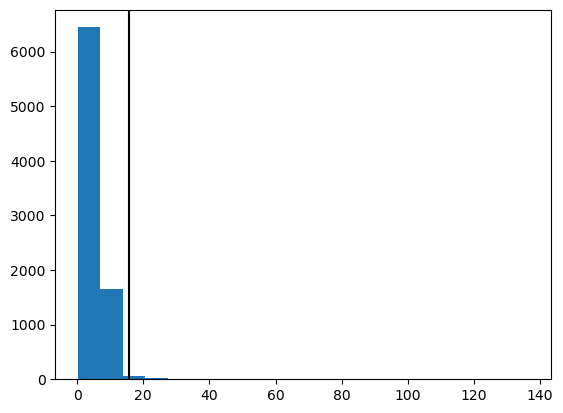

In [64]:
#=====KNN======

#n=round(m.sqrt(len(df_unito)))
n=10
clf = KNN(contamination=0.01, n_neighbors=n, method='mean') 
#scritto nella descrizione del metodo e consigliato da guidotti: 'mean': use the average of all k neighbors as the outlier score

clf.fit(X_standard)

outliers = clf.predict(X_standard)
np.unique(outliers, return_counts=True)

plt.hist(clf.decision_scores_, bins=20)
plt.axvline(np.min(clf.decision_scores_[np.where(outliers==1)]), c='k')
plt.show()

#1% di outliers come scritto nelle slide (contamination)

Numero di outlier trovati: 934 (11.41%)


/var/folders/dx/gml1dzlj4hv40xclhd6scg5r0000gn/T/ipykernel_93952/3334322444.py:25: DeprecationWarning: Calling nonzero on 0d arrays is deprecated, as it behaves surprisingly. Use `atleast_1d(cond).nonzero()` if the old behavior was intended. If the context of this warning is of the form `arr[nonzero(cond)]`, just use `arr[cond]`.
  plt.axvline(np.max(rknn_scores[np.where(out==1)]), c='k', linestyle='--')


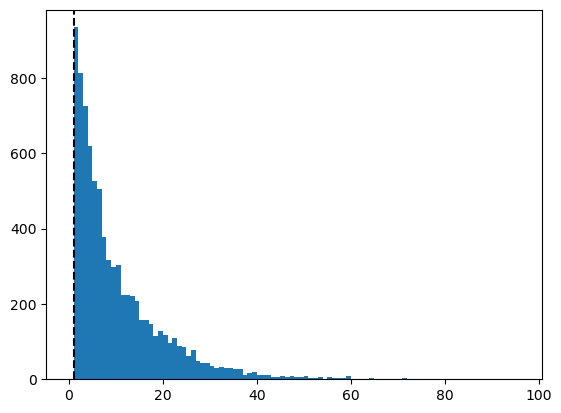

In [65]:
#=====RKNN======
# 1. Trova i k-vicini per ogni punto
k = 10
nbrs = NearestNeighbors(n_neighbors=k).fit(X_standard)
distances, indices = nbrs.kneighbors(X_standard)

# 2. Conta quante volte ogni indice compare nella matrice dei vicini
# 'indices' contiene gli indici dei k vicini per ogni riga
flat_indices = indices.flatten()
counts = np.bincount(flat_indices, minlength=len(X_standard))

# 3. Lo score RkNN è il conteggio (invertito)
# Più il conteggio è basso, più il punto è un outlier
rknn_scores = counts

out= np.percentile(rknn_scores, q=1)

outliers_rknn = np.zeros(len(rknn_scores))
outliers_rknn[rknn_scores <= out] = 1

n_outliers = np.sum(outliers_rknn)
print(f"Numero di outlier trovati: {int(n_outliers)} ({n_outliers/len(df_unito)*100:.2f}%)")

plt.hist(rknn_scores, bins=range(int(np.max(rknn_scores))))
plt.axvline(np.max(rknn_scores[np.where(out==1)]), c='k', linestyle='--')
plt.show()

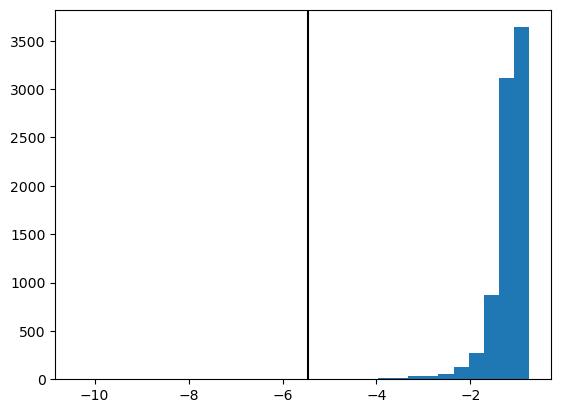

In [ ]:
# ==== ## LOF (sklearn) ====
from sklearn.neighbors import LocalOutlierFactor
from sklearn.model_selection import train_test_split

lof = LocalOutlierFactor(n_neighbors=2, novelty=True)
lof.fit(X_train)

y_pred = lof.predict(X_test)

lof2 = LocalOutlierFactor(n_neighbors=2) # , novelty=True
y_pred2 = lof2.fit_predict(X)
np.unique(y_pred2, return_counts=True)

plt.hist(lof2.negative_outlier_factor_, bins=30)
plt.axvline(np.min(lof2.negative_outlier_factor_[np.where(outliers==1)]), c='k')
plt.show()

#outlier da dove l'ha preso per [np.where(outliers==1)]), c='k') ???

In [ ]:
np.random.seed(42)

# Generate train data
X_inliers = 0.3 * np.random.randn(100, 2)
X_inliers = np.r_[X_inliers + 2, X_inliers - 2]

# Generate some outliers
X_outliers = np.random.uniform(low=-4, high=4, size=(20, 2))
Xa = np.r_[X_inliers, X_outliers]

n_outliers = len(X_outliers)
ground_truth = np.ones(len(Xa), dtype=int)
ground_truth[-n_outliers:] = -1

# fit the model for outlier detection (default)
clf = LocalOutlierFactor(n_neighbors=3, contamination=0.01)
# use fit_predict to compute the predicted labels of the training samples
# (when LOF is used for outlier detection, the estimator has no predict,
# decision_function and score_samples methods).
y_pred = clf.fit_predict(Xa)
n_errors = (y_pred != ground_truth).sum()
X_scores = clf.negative_outlier_factor_

plt.title("Local Outlier Factor (LOF)")
plt.scatter(Xa[:, 0], Xa[:, 1], color='k', s=3., label='Data points')
# plot circles with radius proportional to the outlier scores
radius = (X_scores.max() - X_scores) / (X_scores.max() - X_scores.min())
plt.scatter(Xa[:, 0], Xa[:, 1], s=1000 * radius, edgecolors='r',
            facecolors='none', label='Outlier scores')
plt.axis('tight')
plt.xlim((-5, 5))
plt.ylim((-5, 5))
plt.xlabel("prediction errors: %d" % (n_errors))
legend = plt.legend(loc='upper left')
legend.legend_handles[0]._sizes = [10]
legend.legend_handles[1]._sizes = [20]
plt.show()